In [1]:
import pandas as pd

pd.set_option('display.max_columns', None)

In [2]:
df = pd.read_csv('../Resources/Revised Final Dataset.csv')
df['Month_Year'] = pd.to_datetime(df['Month_Year'], errors='coerce')
df.head()

,Sector,Fruits,Vegetables,Spices,Fuel and light,Health,Month_Year
0,Rural,103.9,101.9,103.1,105.5,104.0,2013-01-01
1,Urban,102.3,102.9,101.8,105.4,104.1,2013-01-01
2,Rural+Urban,103.2,102.2,102.7,105.5,104.0,2013-01-01
3,Rural,104.0,102.4,103.1,106.2,104.4,2013-02-01
4,Urban,103.1,104.9,102.3,105.7,104.7,2013-02-01


In [3]:
df.set_index('Month_Year', inplace=True)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 453 entries, 2013-01-01 to 2025-07-01
Data columns (total 6 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Sector          453 non-null    object 
 1   Fruits          453 non-null    float64
 2   Vegetables      453 non-null    float64
 3   Spices          453 non-null    float64
 4   Fuel and light  453 non-null    float64
 5   Health          453 non-null    float64
dtypes: float64(5), object(1)
memory usage: 24.8+ KB


In [5]:
col_order = ['Sector', 'Fruits', 'Vegetables', 'Spices', 'Fuel and light', 'Health']
df = df[col_order]

In [6]:
df.head()

,Sector,Fruits,Vegetables,Spices,Fuel and light,Health
Month_Year,,,,,,
2013-01-01,Rural,103.9,101.9,103.1,105.5,104.0
2013-01-01,Urban,102.3,102.9,101.8,105.4,104.1
2013-01-01,Rural+Urban,103.2,102.2,102.7,105.5,104.0
2013-02-01,Rural,104.0,102.4,103.1,106.2,104.4
2013-02-01,Urban,103.1,104.9,102.3,105.7,104.7


In [7]:
df = df[df['Sector']=='Urban'].copy()
df = df.asfreq('MS')

In [8]:
df.index.min(), df.index.max()

(Timestamp('2013-01-01 00:00:00'), Timestamp('2025-07-01 00:00:00'))

In [9]:
pd.date_range(start=df.index.min(), end=df.index.max(), freq='MS')

DatetimeIndex(['2013-01-01', '2013-02-01', '2013-03-01', '2013-04-01',
               '2013-05-01', '2013-06-01', '2013-07-01', '2013-08-01',
               '2013-09-01', '2013-10-01',
               ...
               '2024-10-01', '2024-11-01', '2024-12-01', '2025-01-01',
               '2025-02-01', '2025-03-01', '2025-04-01', '2025-05-01',
               '2025-06-01', '2025-07-01'],
              dtype='datetime64[ns]', length=151, freq='MS')

In [10]:
full_range = pd.date_range(start=df.index.min(), end=df.index.max(), freq='MS')

In [11]:
df.index

DatetimeIndex(['2013-01-01', '2013-02-01', '2013-03-01', '2013-04-01',
               '2013-05-01', '2013-06-01', '2013-07-01', '2013-08-01',
               '2013-09-01', '2013-10-01',
               ...
               '2024-10-01', '2024-11-01', '2024-12-01', '2025-01-01',
               '2025-02-01', '2025-03-01', '2025-04-01', '2025-05-01',
               '2025-06-01', '2025-07-01'],
              dtype='datetime64[ns]', name='Month_Year', length=151, freq='MS')

In [12]:
df.isna().sum()

Sector            0
Fruits            0
Vegetables        0
Spices            0
Fuel and light    0
Health            0
dtype: int64

In [13]:
df[df['Vegetables'].isna()]['Vegetables']
df['Vegetables'].interpolate().loc['2019-03-01':'2019-05-01']

Month_Year
2019-03-01    141.2
2019-04-01    150.2
2019-05-01    161.6
Freq: MS, Name: Vegetables, dtype: float64

In [14]:
df['Vegetables'] = df['Vegetables'].interpolate()
df['Vegetables'].isna().sum()

0

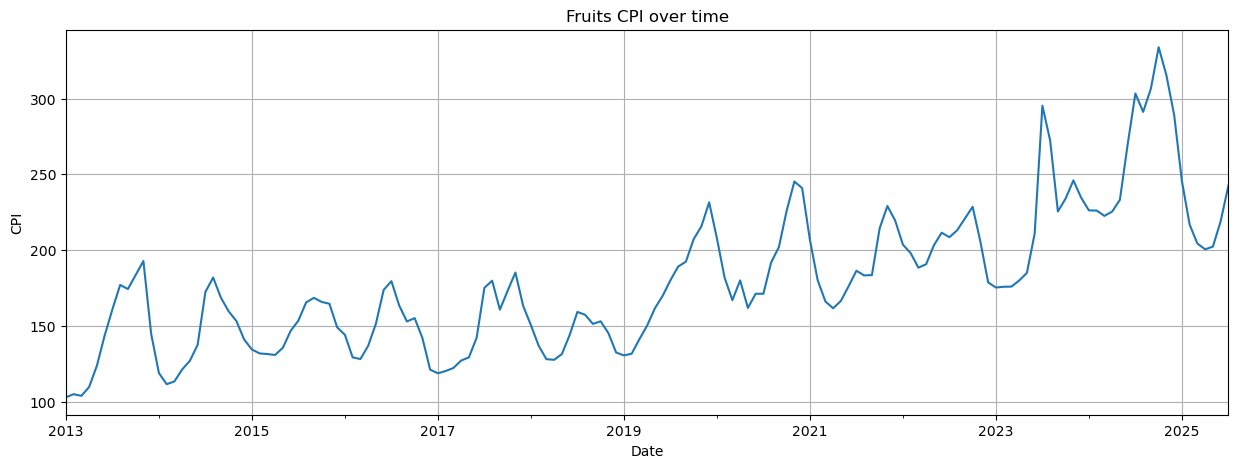

In [15]:
import matplotlib.pyplot as plt
plt.figure(figsize=(15,5))
df['Vegetables'].plot()
plt.title('Fruits CPI over time')
plt.xlabel('Date')
plt.ylabel('CPI')
plt.grid(True)
plt.show()

In [16]:
from statsmodels.tsa.seasonal import STL
stl = STL(df['Vegetables'], period=12)
result = stl.fit()

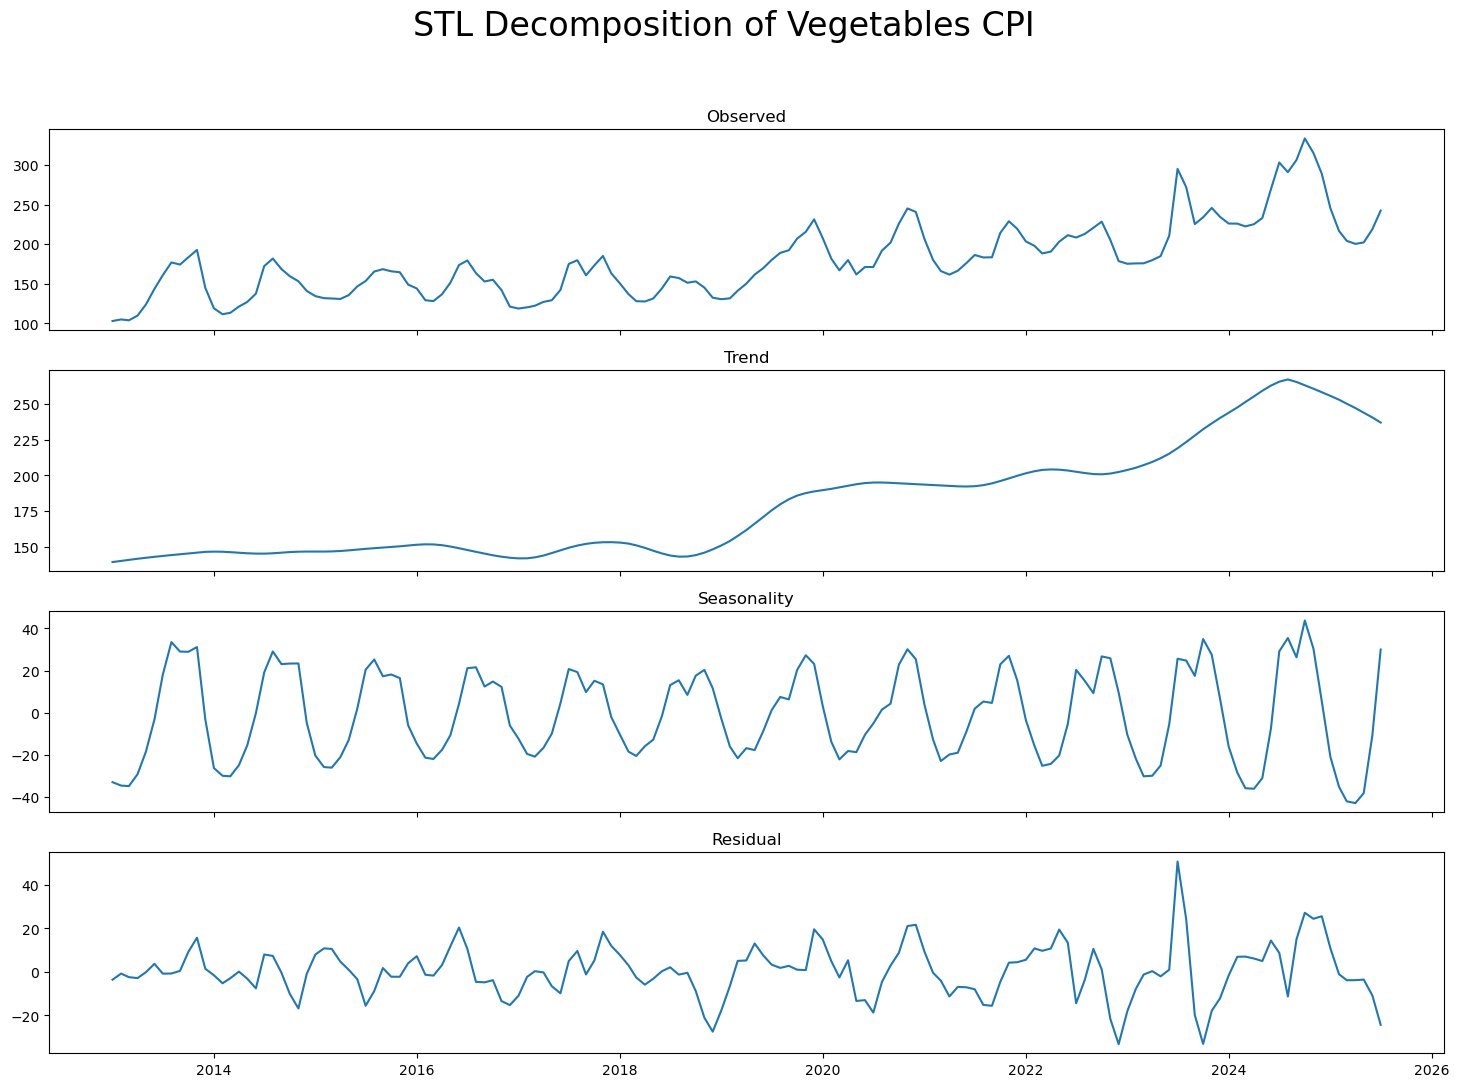

In [17]:
fig, axs = plt.subplots(4, 1, figsize=(18,12), sharex=True)

axs[0].plot(df.index, df['Vegetables'], label='Observed')
axs[0].set_title('Observed')

axs[1].plot(df.index, result.trend, label='Trend')
axs[1].set_title('Trend')

axs[2].plot(df.index, result.seasonal, label='Seasonality')
axs[2].set_title('Seasonality')

axs[3].plot(df.index, result.resid, label='Residual')
axs[3].set_title('Residual')

plt.suptitle('STL Decomposition of Vegetables CPI', fontsize=24)
plt.show()

In [18]:
from statsmodels.tsa.stattools import adfuller

adf_result = adfuller(df['Vegetables'])
adf_result

(-0.24196956243579174,
 0.9333305354707261,
 11,
 139,
 {'1%': -3.4782936965183815,
  '5%': -2.882567574015525,
  '10%': -2.5779830117488745},
 1097.4976405500115)

In [19]:
adf_result[0]

-0.24196956243579174

In [20]:
adf_result[1]

0.9333305354707261

In [21]:
#cannot reject null hypothesis as 0.419428 > 0.05

In [22]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

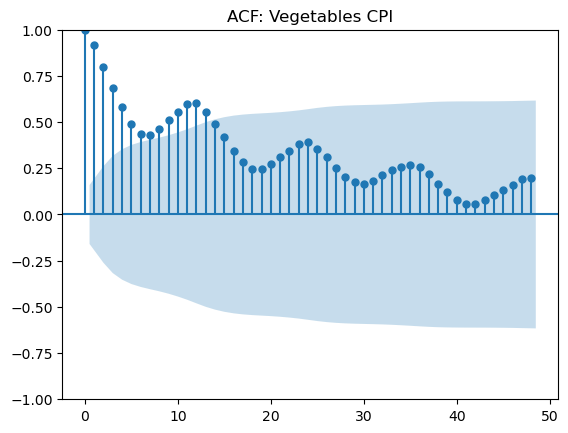

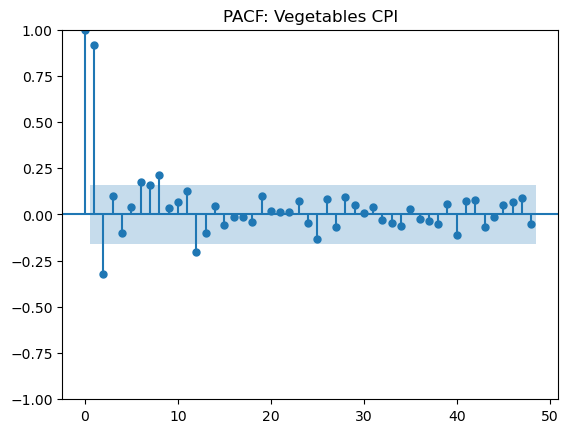

In [23]:
plot_acf(df['Vegetables'], lags=48)
plt.title('ACF: Vegetables CPI')
plt.show()

plot_pacf(df['Vegetables'], lags=48)
plt.title('PACF: Vegetables CPI')
plt.show()

In [24]:
# AR from PACF: sharp drop is from lag 3
# MA from ACF: lags 1 to 3 are significant 

In [25]:
test_size = 12 
train = df['Vegetables'].iloc[0:-test_size]
test = df['Vegetables'].iloc[-test_size:]

In [26]:
from statsmodels.tsa.arima.model import ARIMA

In [27]:
model = ARIMA(train, order=(0,2,1), seasonal_order=(0,1,1,12))
results = model.fit()

results.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                                    SARIMAX Results                                     
========================================================================================
Dep. Variable:                       Vegetables   No. Observations:                  139
Model:             ARIMA(0, 2, 1)x(0, 1, 1, 12)   Log Likelihood                -515.686
Date:                          Sun, 22 Nov 2026   AIC                           1037.372
Time:                                  15:33:34   BIC                           1045.857
Sample:                              01-01-2013   HQIC                          1040.819
                                   - 07-01-2024                                         
Covariance Type:                            opg                                         
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ma.L1         -0.9984      0.916     -1.089      0.276      -2.794       0.798
ma.S.L12      -0.9880      1.399     -0.706      0.480      -3.730       1.754
sigma2       169.6039    283.366      0.599      0.549    -385.782     724.990
===================================================================================
Ljung-Box (L1) (Q):                   5.16   Jarque-Bera (JB):               159.80
Prob(Q):                              0.02   Prob(JB):                         0.00
Heteroskedasticity (H):               3.03   Skew:                             0.68
Prob(H) (two-sided):                  0.00   Kurtosis:                         8.37
===================================================================================

Warnings:
[1] Covariance matrix calculated using the outer product of gradients (complex-step).
"""

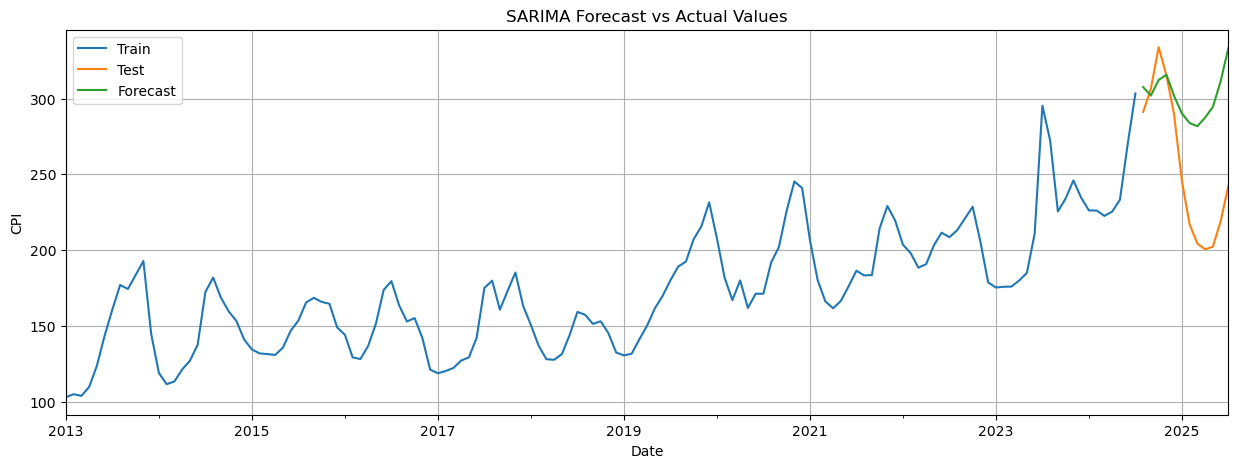

In [28]:
sarima_forecast = results.forecast(steps=test_size)

plt.figure(figsize=(15, 5))

train.plot(label='Train')
test.plot(label='Test')

sarima_forecast.index = test.index
sarima_forecast.plot(label='Forecast')

plt.title('SARIMA Forecast vs Actual Values')
plt.xlabel('Date')
plt.ylabel('CPI')
plt.legend()
plt.grid(True)

plt.show()

In [29]:
import numpy as np
from sklearn.metrics import mean_squared_error

rmse = mean_squared_error(test, sarima_forecast)
tmse = np.sqrt(rmse)
tmse

62.107876749963204

In [30]:
s = 12

p_values = [0,1,2]
d_values = [1]
q_values = [0,1,2]

P_values = [0, 1, 2]
D_values = [1]
Q_values = [0, 1, 2]

In [31]:
param_grid = [((p, d, q), (P, D, Q, s))
 for p in p_values
 for d in d_values
 for q in q_values
 for P in P_values
 for D in D_values
 for Q in Q_values]

len(param_grid)

81

In [32]:
from sklearn.model_selection import TimeSeriesSplit

In [33]:
X = df['Vegetables']
tscv = TimeSeriesSplit(n_splits=3, test_size=12)
tscv

TimeSeriesSplit(gap=0, max_train_size=None, n_splits=3, test_size=12)

In [34]:
len(list(tscv.split(X)))

3

In [35]:
list(tscv.split(X))

[(array([  0,   1,   2,   3,   4,   5,   6,   7,   8,   9,  10,  11,  12,
          13,  14,  15,  16,  17,  18,  19,  20,  21,  22,  23,  24,  25,
          26,  27,  28,  29,  30,  31,  32,  33,  34,  35,  36,  37,  38,
          39,  40,  41,  42,  43,  44,  45,  46,  47,  48,  49,  50,  51,
          52,  53,  54,  55,  56,  57,  58,  59,  60,  61,  62,  63,  64,
          65,  66,  67,  68,  69,  70,  71,  72,  73,  74,  75,  76,  77,
          78,  79,  80,  81,  82,  83,  84,  85,  86,  87,  88,  89,  90,
          91,  92,  93,  94,  95,  96,  97,  98,  99, 100, 101, 102, 103,
         104, 105, 106, 107, 108, 109, 110, 111, 112, 113, 114]),
  array([115, 116, 117, 118, 119, 120, 121, 122, 123, 124, 125, 126])),
 (array([  0,   1,   2,   3,   4,   5,   6,   7,   8,   9,  10,  11,  12,
          13,  14,  15,  16,  17,  18,  19,  20,  21,  22,  23,  24,  25,
          26,  27,  28,  29,  30,  31,  32,  33,  34,  35,  36,  37,  38,
          39,  40,  41,  42,  43,  44,  45,  46,

In [36]:
from tqdm import tqdm
import numpy as np

metrics = []

for order, seasonal_order in tqdm(param_grid):
    split_rmse = []

    for train_idx, test_idx in tscv.split(X):
        X_train = X.iloc[train_idx]
        X_test = X.iloc[test_idx]

        model = ARIMA(X_train, order=order, seasonal_order=seasonal_order)
        results = model.fit()

        X_pred = results.forecast(steps=len(X_test))
        rmse = np.sqrt(mean_squared_error(X_test, X_pred))
        split_rmse.append(rmse)

    mean_rmse = np.mean(split_rmse)
    std_rmse = np.std(split_rmse)

    metrics.append(
        {'order': order,
         'seasonal_order': seasonal_order,
         'rmse_mean': mean_rmse,
         'rmse_std': std_rmse}
    )

  0%|          | 0/81 [00:00<?, ?it/s]

/opt/anaconda3/lib/python3.12/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


/opt/anaconda3/lib/python3.12/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


/opt/anaconda3/lib/python3.12/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


/opt/anaconda3/lib/python3.12/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


/opt/anaconda3/lib/python3.12/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


... (32 outputs left out)

/opt/anaconda3/lib/python3.12/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


/opt/anaconda3/lib/python3.12/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


/opt/anaconda3/lib/python3.12/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


100%|██████████| 81/81 [03:57<00:00,  2.93s/it]

In [37]:
metrics_df = pd.DataFrame(metrics)
metrics_df

,order,seasonal_order,rmse_mean,rmse_std
0,"(0, 1, 0)","(0, 1, 0, 12)",47.684630,5.206645
1,"(0, 1, 0)","(0, 1, 1, 12)",46.689579,7.983380
2,"(0, 1, 0)","(0, 1, 2, 12)",46.017620,6.469197
3,"(0, 1, 0)","(1, 1, 0, 12)",51.534656,6.001256
4,"(0, 1, 0)","(1, 1, 1, 12)",45.845799,6.632963
...,...,...,...,...
76,"(2, 1, 2)","(1, 1, 1, 12)",44.871130,14.896957
77,"(2, 1, 2)","(1, 1, 2, 12)",47.685309,19.034921
78,"(2, 1, 2)","(2, 1, 0, 12)",59.610954,20.069738
79,"(2, 1, 2)","(2, 1, 1, 12)",46.882479,15.917329


In [38]:
metrics_df.sort_values(by='rmse_mean', ascending=True)

,order,seasonal_order,rmse_mean,rmse_std
46,"(1, 1, 2)","(0, 1, 1, 12)",34.445006,1.207888
49,"(1, 1, 2)","(1, 1, 1, 12)",34.549821,0.413784
47,"(1, 1, 2)","(0, 1, 2, 12)",34.557105,0.180606
52,"(1, 1, 2)","(2, 1, 1, 12)",35.409334,0.581835
53,"(1, 1, 2)","(2, 1, 2, 12)",35.644035,1.419409
...,...,...,...,...
30,"(1, 1, 0)","(1, 1, 0, 12)",63.021134,22.510765
15,"(0, 1, 1)","(2, 1, 0, 12)",63.099027,22.844889
42,"(1, 1, 1)","(2, 1, 0, 12)",63.930625,23.900812
24,"(0, 1, 2)","(2, 1, 0, 12)",64.653367,25.126850


In [39]:
model = ARIMA(train, order=(1,1,2), seasonal_order=(4,0,1,12))
results = model.fit()

results.summary()

/opt/anaconda3/lib/python3.12/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


<class 'statsmodels.iolib.summary.Summary'>
"""
                                     SARIMAX Results                                      
==========================================================================================
Dep. Variable:                         Vegetables   No. Observations:                  139
Model:             ARIMA(1, 1, 2)x(4, 0, [1], 12)   Log Likelihood                -544.788
Date:                            Sun, 22 Nov 2026   AIC                           1107.577
Time:                                    15:37:36   BIC                           1133.922
Sample:                                01-01-2013   HQIC                          1118.283
                                     - 07-01-2024                                         
Covariance Type:                              opg                                         
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.6464      0.124      5.227      0.000       0.404       0.889
ma.L1         -0.4351      0.136     -3.195      0.001      -0.702      -0.168
ma.L2         -0.4591      0.094     -4.860      0.000      -0.644      -0.274
ar.S.L12       1.0744      0.284      3.780      0.000       0.517       1.632
ar.S.L24      -0.0116      0.191     -0.061      0.952      -0.385       0.362
ar.S.L36      -0.2922      0.210     -1.388      0.165      -0.705       0.120
ar.S.L48       0.2278      0.137      1.667      0.095      -0.040       0.496
ma.S.L12      -0.9590      1.087     -0.883      0.377      -3.089       1.170
sigma2       134.7887    115.913      1.163      0.245     -92.397     361.974
===================================================================================
Ljung-Box (L1) (Q):                   0.00   Jarque-Bera (JB):               254.31
Prob(Q):                              0.99   Prob(JB):                         0.00
Heteroskedasticity (H):               2.55   Skew:                             1.06
Prob(H) (two-sided):                  0.00   Kurtosis:                         9.30
===================================================================================

Warnings:
[1] Covariance matrix calculated using the outer product of gradients (complex-step).
"""

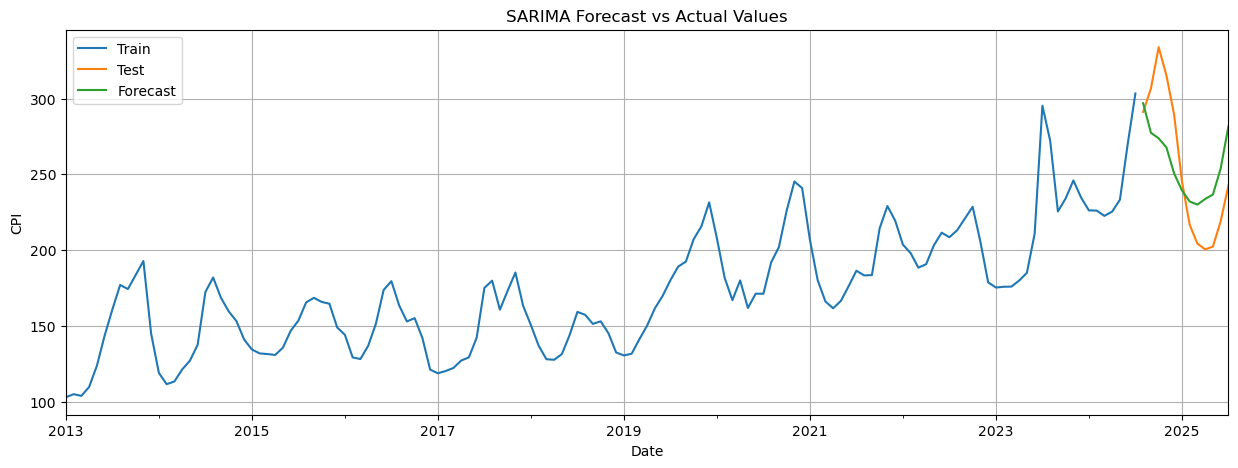

In [40]:
sarima_forecast = results.forecast(steps=test_size)

plt.figure(figsize=(15, 5))

train.plot(label='Train')
test.plot(label='Test')

sarima_forecast.index = test.index
sarima_forecast.plot(label='Forecast')

plt.title('SARIMA Forecast vs Actual Values')
plt.xlabel('Date')
plt.ylabel('CPI')
plt.legend()
plt.grid(True)

plt.show()

In [41]:
import numpy as np
from sklearn.metrics import mean_squared_error

rmse = mean_squared_error(test, sarima_forecast)
tmse = np.sqrt(rmse)
tmse

34.41408042266477

In [42]:
results = model.fit()


import joblib
joblib.dump(results, 'vegetables-urban.pkl')

/opt/anaconda3/lib/python3.12/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


['vegetables-urban.pkl']